ID,ra,dec,GAIA,Tmag
str9,float64,float64,str18,float64
468750384,21.2832800274803,75.6761400820579,560017010452668416,13.0766


Using LSPM J0125+7540: TIC 468750384
Available sectors: [18, 19, 25, 58, 59, 73, 78, 79, 85, 86]
INFO: Found cached file /Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT/TESS/hlsp_qlp_tess_ffi_s0018-0000000468750384_tess_v01_llc.fits with expected size 72000. [astroquery.query]
Sector 18: best period = 0.3522 d, power = 0.307
Required power:
1sigma: 0.017
2sigma: 0.022
3sigma: 0.027

INFO: Found cached file /Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT/TESS/hlsp_qlp_tess_ffi_s0019-0000000468750384_tess_v01_llc.fits with expected size 74880. [astroquery.query]
Sector 19: best period = 0.3524 d, power = 0.569
Required power:
1sigma: 0.018
2sigma: 0.022
3sigma: 0.029

INFO: Found cached file /Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT/TESS/hlsp_qlp_tess_ffi_s0025-0000000468750384_tess_v01_llc.fits with expected size 74880. [astroquery.query]
Sector 25: best period = 0.3521 d, power = 0.362
Required power:
1sigma: 0.020
2sigma: 0.026
3sigma: 0.03

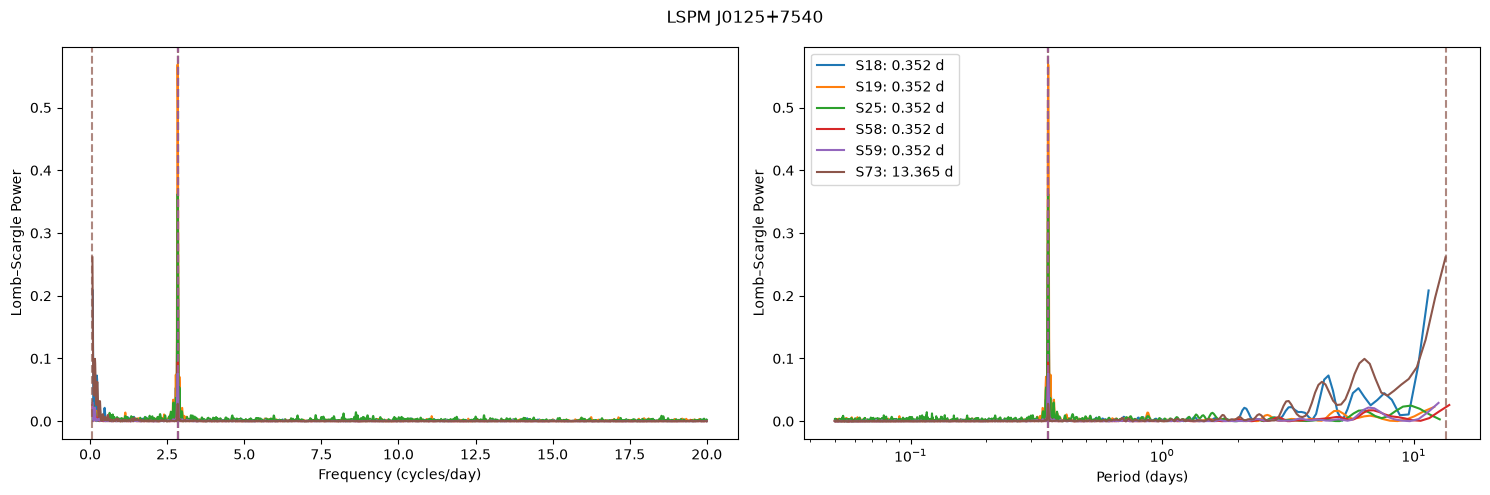

In [8]:
from pathlib import Path

from astroquery.mast import Catalogs, Observations
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.timeseries import LombScargle

target = "LSPM J0125+7540"

matches = Catalogs.query_object(target, catalog="TIC", radius=5/3600)
display(matches[["ID", "ra", "dec", "GAIA", "Tmag"]])
tic = str(matches[0]["ID"])

print(f"Using {target}: TIC {tic}")

obs = Observations.query_criteria(provenance_name="QLP", target_name=tic)
if not len(obs):
    raise ValueError(f"No QLP light curves listed for TIC {tic}.")

sectors = sorted({int(s) for s in obs["sequence_number"]})
print("Available sectors:", sectors)

folder = Path.home() / "Desktop" / "UNC YEAR 3" / "ASTR 519" / "FINAL PROJECT" / "TESS"
folder.mkdir(parents=True, exist_ok=True)

min_period = 0.05  # days
max_period = 15.0  # days, before the two-cycle cutoff
fap_method = "bootstrap"  # Change to "baluev" for a faster run
fap_kwargs = {"n_bootstraps": 5000} if fap_method == "bootstrap" else None
probs = np.array([0.6827, 0.9545, 0.9973])

fig, (ax_freq, ax_period) = plt.subplots(1, 2, figsize=(15, 5))

for i,sector in enumerate(sectors):
    if (i > 5):
        continue
    selected = obs[obs["sequence_number"] == sector]
    products = Observations.get_product_list(selected)
    lcs = [p for p in products if p["productFilename"].endswith("_llc.fits")]
    if not lcs:
        print(f"Sector {sector}: no QLP FITS light curve.")
        continue

    p = lcs[0]
    path = folder / p["productFilename"]
    status, message, _ = Observations.download_file(p["dataURI"], local_path=str(path))
    if status != "COMPLETE":
        raise RuntimeError(message or status)

    with fits.open(path) as hdus:
        lc = hdus[1].data
        t, flux, quality = lc["TIME"], lc["SAP_FLUX"], lc["QUALITY"]
        keep = (quality == 0) & np.isfinite(t) & np.isfinite(flux)
        t, flux = t[keep], flux[keep]

    unique_t = np.unique(t)
    if len(unique_t) < 10 or np.ptp(flux) == 0:
        print(f"Sector {sector}: insufficient usable data.")
        continue

    ## Search range: require at least two cycles in the baseline.
    longest = min(max_period, np.ptp(t) / 2)
    shortest = max(min_period, 2 * np.median(np.diff(unique_t)))
    if shortest >= longest:
        print(f"Sector {sector}: no usable period range.")
        continue

    ls = LombScargle(t - t.min(), flux)
    frequency, power = ls.autopower(
        minimum_frequency=1 / longest,
        maximum_frequency=1 / shortest,
    )

    good = np.isfinite(power) & (frequency >= 1 / longest) & (frequency <= 1 / shortest)
    if not good.any():
        continue

    f, pwr = frequency[good], power[good]
    best_idx = np.argmax(pwr)
    best_frequency = f[best_idx]
    best_period = 1 / best_frequency

    ## Plot in frequency space.
    line, = ax_freq.plot(f, pwr, label=f"Sector {sector}")
    color = line.get_color()
    ax_freq.axvline(best_frequency, linestyle="--", color=color, alpha=0.7)

    ## Plot in period space.
    ax_period.plot(1 / f, pwr, color=color,
                   label=f"S{sector}: {best_period:.3f} d")
    ax_period.axvline(best_period, linestyle="--", color=color, alpha=0.7)

    ## Calculate false-alarm levels on this sector's LS object.
    required_power = ls.false_alarm_level(
        1 - probs,
        method=fap_method,
        minimum_frequency=f.min(),
        maximum_frequency=f.max(),
        method_kwds=fap_kwargs,
    )

    print(f"Sector {sector}: best period = {best_period:.4f} d, power = {pwr[best_idx]:.3f}")
    print("Required power:")
    for sigma, level in enumerate(required_power, start=1):
        print(f"{sigma}sigma: {level:.3f}")
    print()

ax_freq.set_xlabel("Frequency (cycles/day)")
ax_freq.set_ylabel("Lomb–Scargle Power")

ax_period.set_xlabel("Period (days)")
ax_period.set_ylabel("Lomb–Scargle Power")
ax_period.set_xscale("log")
ax_period.legend()

fig.suptitle(f"{target}")
fig.tight_layout()
plt.show()

TIC 233521211
    ID            GAIA            TWOMASS      HIP TYC
--------- ------------------- ---------------- --- ---
233521211 2123230006336124672 18044134+4951512  --  --
Filename: /Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT/TESS/hlsp_qlp_tess_ffi_s0014-0000000233521211_tess_v01_llc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      29   ()      
  1  LIGHTCURVE    1 BinTableHDU     65   1241R x 13C   [D, J, E, E, E, J, J, E, E, E, E, E, E]   
<bound method Header.items of XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   56 / length of dimension 1                          
NAXIS2  =                 1241 / length of dimension 2                          
PCOUNT  =                    0 / number

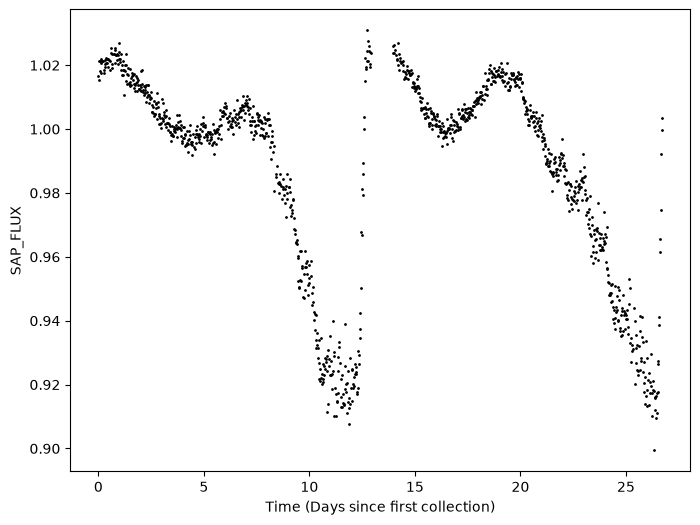

In [25]:
from astropy.io import fits
from astropy.utils.data import download_file
from astroquery.mast import Catalogs

image_file = "/Users/nwansbacher/Desktop/UNC YEAR 3/ASTR 519/FINAL PROJECT/TESS/hlsp_qlp_tess_ffi_s0014-0000000233521211_tess_v01_llc.fits"
tic = int(fits.getval(image_file, "TICID", ext=0))
print(f"TIC {tic}")  # TIC 233521211

row = Catalogs.query_criteria(catalog="TIC", ID=int(tic))
print(row[["ID", "GAIA", "TWOMASS", "HIP", "TYC"]])

hdu_list = fits.open(image_file)
hdu_list.info()
image_data = hdu_list[1].data
header = hdu_list[1].header

print(header.items)
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

with fits.open(image_file) as hdu_list:
    lc = hdu_list[1].data
    print(lc.columns.names)
    tess_bjds = lc['TIME']
    flux_column = 'SAP_FLUX'  
    fluxes = lc[flux_column]
    good = (lc['QUALITY'] == 0) & np.isfinite(tess_bjds) & np.isfinite(fluxes)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(tess_bjds[good]-min(tess_bjds[good]), fluxes[good], 'k.', markersize=2)
    ax.set(xlabel='Time (Days since first collection)', ylabel=flux_column)
    plt.show()